# Non-coplanar 2

In [12]:
import numpy as np
import scipy as sp
from scipy.interpolate import CubicSpline, RectBivariateSpline
from scipy import interpolate
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.colors import Normalize
from matplotlib import cm, colors as mcolors
import seaborn as sns
from tqdm import trange
from matplotlib import cm
from scipy.special import erf
from scipy.spatial import cKDTree
from mpl_toolkits.mplot3d import Axes3D
import os

In [13]:
mu = np.array([
    [0.4,0.7, 0.2],
    [1,-0.5,-0.2],
    [-0.2,-0.6,0.4],
    [-0.5,0.2,-0.6]
]).T

closed_points = np.vstack([mu.T, mu.T[0]])
t = np.arange(len(closed_points))
cs_x = CubicSpline(t, closed_points[:, 0], bc_type='periodic')
cs_y = CubicSpline(t, closed_points[:, 1], bc_type='periodic')
cs_z = CubicSpline(t, closed_points[:, 2], bc_type='periodic')
t_new = np.linspace(t.min(), t.max(), 100)
x_new = cs_x(t_new)
y_new = cs_y(t_new)
z_new = cs_z(t_new)
R = np.vstack([cs_x(t_new), cs_y(t_new), cs_z(t_new)]).T

In [14]:
def get_frenet_frame_at_t(t_val):
    r_prime = np.array([cs_x(t_val, 1), cs_y(t_val, 1), cs_z(t_val, 1)])
    r_double_prime = np.array([cs_x(t_val, 2), cs_y(t_val, 2), cs_z(t_val, 2)])
    
    T = r_prime / np.linalg.norm(r_prime)
    
    dot_product = np.dot(r_double_prime, T)
    N_unnormalized = r_double_prime - dot_product * T
    N = N_unnormalized / np.linalg.norm(N_unnormalized)
    
    B = np.cross(T, N)
    return T, N, B

tube_radius = 0.4
eps_curl = 1e-5         # finite-difference step for curl
n_samples = 1000
xi = 0.75

def Psi(r):
    return np.exp((-r**2)/(2*xi**2))

sample_t = np.linspace(t.min(), t.max(), n_samples)
R_samples = np.vstack([cs_x(sample_t), cs_y(sample_t), cs_z(sample_t)]).T

T_samples = np.zeros_like(R_samples)
N_samples = np.zeros_like(R_samples)
B_samples = np.zeros_like(R_samples)

for i, tt in enumerate(sample_t):
    T, N, B = get_frenet_frame_at_t(tt)
    T_samples[i] = T
    N_samples[i] = N
    B_samples[i] = B

tree = cKDTree(R_samples)


def vector_potential_A_batch(pts):

    pts = np.asarray(pts).reshape(-1, 3)
    Npts = pts.shape[0]

    dists, idxs = tree.query(pts)                
    Rloc = R_samples[idxs]                       
    Tloc = T_samples[idxs]
    Nloc = N_samples[idxs]
    Bloc = B_samples[idxs]

    rel = pts - Rloc                             
    projN = np.einsum('ij,ij->i', rel, Nloc)     
    projB = np.einsum('ij,ij->i', rel, Bloc)
    rho = np.hypot(projN, projB)

    theta = np.arctan2(projB, projN)             # (N,)

    sinth = np.sin(theta)[:, None]
    costh = np.cos(theta)[:, None]
    e_theta = -sinth * Nloc + costh * Bloc      # (N,3)

    A = np.zeros_like(pts)
    inside_mask = rho < tube_radius
    if inside_mask.any():
        A[inside_mask] = (Psi(rho[inside_mask])[:, None] * e_theta[inside_mask])

    return A


In [15]:
def curlA_batch(pts):

    pts = np.asarray(pts).reshape(-1, 3)
    Npts = pts.shape[0]
    eps = eps_curl

    pxp = pts + np.array([eps, 0.0, 0.0])
    pxm = pts - np.array([eps, 0.0, 0.0])
    pyp = pts + np.array([0.0, eps, 0.0])
    pym = pts - np.array([0.0, eps, 0.0])
    pzp = pts + np.array([0.0, 0.0, eps])
    pzm = pts - np.array([0.0, 0.0, eps])

    A_xp = vector_potential_A_batch(pxp)   # shape (N,3)
    A_xm = vector_potential_A_batch(pxm)
    A_yp = vector_potential_A_batch(pyp)
    A_ym = vector_potential_A_batch(pym)
    A_zp = vector_potential_A_batch(pzp)
    A_zm = vector_potential_A_batch(pzm)

    dAx_dy = (A_yp[:, 0] - A_ym[:, 0]) / (2 * eps)
    dAx_dz = (A_zp[:, 0] - A_zm[:, 0]) / (2 * eps)

    dAy_dx = (A_xp[:, 1] - A_xm[:, 1]) / (2 * eps)
    dAy_dz = (A_zp[:, 1] - A_zm[:, 1]) / (2 * eps)

    dAz_dx = (A_xp[:, 2] - A_xm[:, 2]) / (2 * eps)
    dAz_dy = (A_yp[:, 2] - A_ym[:, 2]) / (2 * eps)

    curl_x = dAz_dy - dAy_dz
    curl_y = dAx_dz - dAz_dx
    curl_z = dAy_dx - dAx_dy

    curl = np.vstack([curl_x, curl_y, curl_z]).T
    return curl

In [16]:
def vector_field(pts):

    pts = np.asarray(pts)
    if pts.ndim == 1:
        return curlA_batch(pts[None, :])[0]
    elif pts.ndim == 2:
        return curlA_batch(pts)
    else:
        raise ValueError("pts must be shape (3,) or (N,3)")

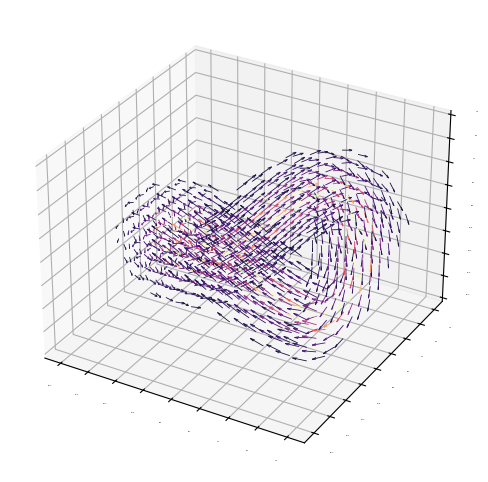

In [23]:
n = 15  
x_range = np.linspace(-1, 1, n)
y_range = np.linspace(-1, 1, n)
z_range = np.linspace(-1, 1, n)
X, Y, Z = np.meshgrid(x_range, y_range, z_range, indexing='ij')

grid_points = np.vstack([X.ravel(), Y.ravel(), Z.ravel()]).T

V = vector_field(grid_points)
Vx, Vy, Vz = V[:, 0], V[:, 1], V[:, 2]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

magnitude = np.linalg.norm(V, axis=1)

eps = 1e-12
Vx_dir = Vx / (magnitude + eps)
Vy_dir = Vy / (magnitude + eps)
Vz_dir = Vz / (magnitude + eps)

vmin = np.percentile(magnitude, 1)   # clip lower 1%
vmax = np.percentile(magnitude, 99)  # clip upper 1%

norm = mcolors.Normalize(vmin=vmin, vmax=vmax, clip=True)
cmap = cm.magma
colors_rgba = cmap(norm(magnitude))   # shape (N,4)

ax.quiver(
    grid_points[:,0], grid_points[:,1], grid_points[:,2],
    Vx_dir, Vy_dir, Vz_dir,
    length=0.12, normalize=False,
    colors=colors_rgba, linewidth=0.6
)

ax.tick_params(axis='x', which='both', length=0, labelsize=0)
ax.tick_params(axis='y', which='both', length=0, labelsize=0)
ax.tick_params(axis='z', which='both', length=0, labelsize=0)

plt.show()


In [7]:
def simulate_process_EM(F,X0,T,dt,nu):

    Nt = int(T/dt)
    M = np.shape(X0)[0]
    X = np.zeros((M,Nt))
    X[:,0] = X0
    
    for t in trange(Nt-1, desc="Simulating", leave=False):
        X[:,t+1] = X[:,t] + dt*(F(X[:,t])) + nu*np.random.normal(0, np.sqrt(dt), size=M)
        
    return X

In [8]:
def gaussian_potential(x,mu,A,sigma):
    
    N = mu.shape[1]
    V = 0

    for j in range(0,N):
        V -= A[j]*np.exp(-((np.linalg.norm(x-mu[:,j]))**2)/(2*(sigma[j]**2)))
    
    return V

def grad_gaussian_potential(x,mu,A,sigma):
    
    N = mu.shape[1]
    M = mu.shape[0]
    V = np.zeros(M)

    for j in range(0,N):
        V += (A[j]/sigma[j]**2)*(x-mu[:,j])*np.exp(-((np.linalg.norm(x-mu[:,j]))**2)/(2*(sigma[j]**2)))

    return V

In [25]:
sigma = 0.325*np.ones(mu.shape[1])
A = 0.5*np.ones(mu.shape[1])

def V(x):
    return gaussian_potential(x,mu,A,sigma)

def gradV(x):
    return grad_gaussian_potential(x,mu,A,sigma)

In [10]:
nu = 0.155

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

alpha = 4000

def f(x):
    return alpha*vector_field(x)/piZ(x)-gradV(x)  

In [11]:
X0 = np.array([0,0,0]) #np.random.multivariate_normal([0,0,0],0*np.eye(3));
T = 5000; dt = 0.005;
time = np.linspace(0,T,int(T/dt))

x = simulate_process_EM(f,X0,T,dt,nu)

KeyboardInterrupt: 

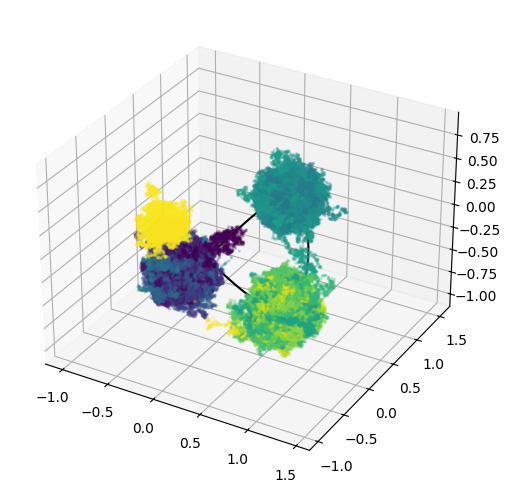

In [17]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(1, 1, 1, projection='3d')

ax.plot(x_new, y_new, z_new, c='k', zorder=3)

sc = ax.scatter(x[0,:], x[1,:], x[2,:],
                c=time, cmap='viridis', s=2, alpha=0.2,
                rasterized=True, zorder=1)

ax.scatter(mu[0,:], mu[1,:], mu[2,:], color='r', s=100, zorder=4)

ax.set_rasterization_zorder(1)

plt.tight_layout()

plt.show()

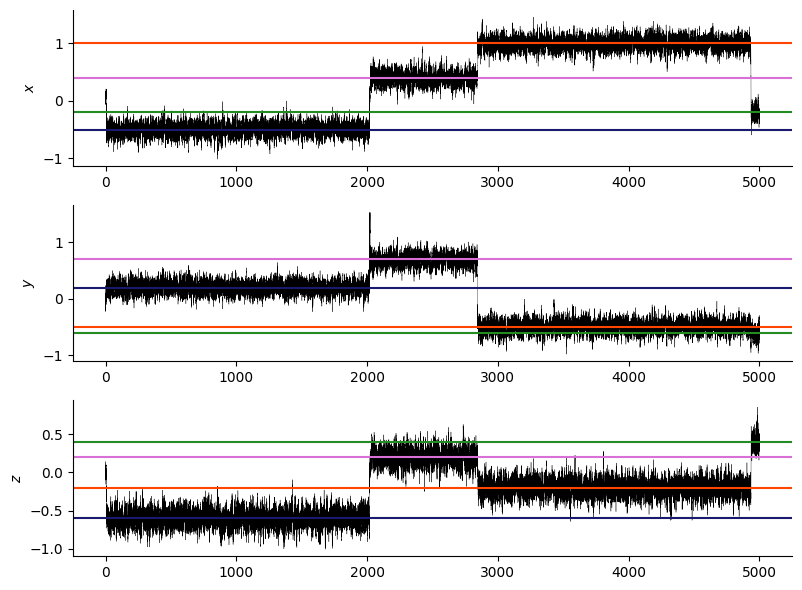

In [15]:
fig, ax = plt.subplots(3,1)

fig.set_size_inches(8,6)
Nt=int(T/dt)
time_T = np.linspace(0,T,Nt)

ax[0].plot(time_T, x[0,:],'k',linewidth = 0.25)
ax[1].plot(time_T, x[1,:],'k',linewidth = 0.25)
ax[2].plot(time_T, x[2,:],'k',linewidth = 0.25)

labels = [r'$x$',r'$y$',r'$z$']
attractor_colors = ['orchid','orangered','forestgreen','midnightblue']
for i in range(0,3):
    for j in range(0,4):
        ax[i].axhline(mu[i,j],color = attractor_colors[j])
    ax[i].set_ylabel(labels[i])

sns.despine()
plt.tight_layout()
plt.show()

In [27]:
xmin = -1; xmax = 1
ymin = -1; ymax = 1
zmin = -1; zmax = 1

grid_density = 7
x_range = np.linspace(xmin, xmax, grid_density)
y_range = np.linspace(ymin, ymax, grid_density)
z_range = np.linspace(zmin, zmax, grid_density)
X, Y, Z = np.meshgrid(x_range, y_range, z_range)

U, V_, W = np.zeros(X.shape), np.zeros(X.shape), np.zeros(X.shape)
U_norm, V_norm, W_norm = np.zeros(X.shape), np.zeros(X.shape), np.zeros(X.shape)
magnitude = np.zeros(X.shape)

for i in trange(X.shape[0], desc = 'Building vector field on grid'):
    for j in range(X.shape[1]):
        for k in range(X.shape[2]):
            point = np.array([X[i, j, k], Y[i, j, k], Z[i, j, k]])
            U[i, j, k], V_[i, j, k], W[i, j, k] = f(point)
            magnitude[i, j, k] = np.linalg.norm(np.array([U[i, j, k], V_[i, j, k], W[i, j, k]])) + 1e-11
            U_norm[i, j, k] = U[i, j, k]/magnitude[i, j, k]
            V_norm[i, j, k] = V_[i, j, k]/magnitude[i, j, k]
            W_norm[i, j, k] = W[i, j, k]/magnitude[i, j, k]

X_flat, Y_flat, Z_flat = X.flatten(), Y.flatten(), Z.flatten()
magnitudes_flat = magnitude.flatten()
magnitudes_flat = (magnitudes_flat-np.min(magnitudes_flat))/np.max(magnitudes_flat)

vmin = np.percentile(magnitudes_flat, 1)   # clip lower 1%
vmax = np.percentile(magnitudes_flat, 99)  # clip upper 1%

norm = mcolors.Normalize(vmin=vmin, vmax=vmax, clip=True)
cmap = cm.magma
colors_rgba = cmap(norm(magnitudes_flat))   # shape (N,4)

Building vector field on grid: 100%|██████████████| 7/7 [00:00<00:00, 20.06it/s]


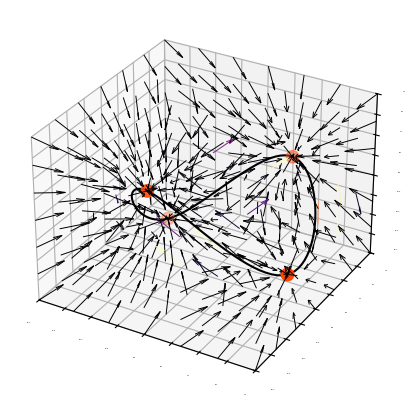

In [32]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection='3d')

cmap = cm.viridis 
colors = cmap(magnitudes_flat)
ax.quiver(X, Y, Z, U_norm, V_norm, W_norm,length=0.25,
          colors=colors_rgba,arrow_length_ratio=0.3, linewidth=0.7)
ax.scatter(mu[0,:], mu[1,:], mu[2,:], c='orangered', s=80)
ax.plot(x_new, y_new, z_new, c='k')
ax.set_xlim([-1,1])
ax.set_ylim([-1,1])
ax.set_zlim([-1,1])
ax.tick_params(axis='x', which='both', length=0, labelsize=0)
ax.tick_params(axis='y', which='both', length=0, labelsize=0)
ax.tick_params(axis='z', which='both', length=0, labelsize=0)

plt.show()

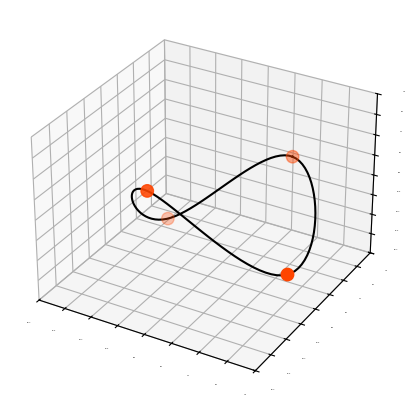

In [33]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection='3d')

cmap = cm.viridis 
colors = cmap(magnitudes_flat)
ax.scatter(mu[0,:], mu[1,:], mu[2,:], c='orangered', s=80)
ax.plot(x_new, y_new, z_new, c='k')
ax.set_xlim([-1,1])
ax.set_ylim([-1,1])
ax.set_zlim([-1,1])
ax.tick_params(axis='x', which='both', length=0, labelsize=0)
ax.tick_params(axis='y', which='both', length=0, labelsize=0)
ax.tick_params(axis='z', which='both', length=0, labelsize=0)

plt.show()